In [1]:
import os
# os.environ["CUDA_VISIBLE_DEVICES"] = ""
import jax

%load_ext autoreload
%autoreload 2

In [2]:
import keypoint_moseq as kpms
import logging

# Clear any existing handlers (important in interactive environments)
for handler in logging.root.handlers[:]:
    logging.root.removeHandler(handler)

# Configure logging once
logging.basicConfig(
    filename='model_run.log',
    level=logging.INFO,
    format='%(asctime)s:%(levelname)s:%(message)s'
)
logging.info("Test log: Notebook execution started.")

project_dir = 'jonathan_ifdn'
config = lambda: kpms.load_config(project_dir)

In [3]:
from tqdm.notebook import tqdm
from jax_moseq.utils import set_mixed_map_iters
set_mixed_map_iters(32)

In [4]:
dlc_config = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/SplitWithGPU_link/config.yaml'
kpms.setup_project(project_dir, deeplabcut_config=dlc_config)

The directory `jonathan_ifdn` already exists. Use `overwrite=True` or
pick a different name


In [5]:
import numpy as np
import pandas as pd

In [6]:
# Import our new modular functions.
from update_config import update_config  # now returns new_mask
from trimming import create_trimmed_coords_and_confs
from batching import create_batches

In [7]:
from trimming import create_trimmed_coords_and_confs
# from batching import create_batches

# Setup pretty printer
print("--- Initial Setup Complete ---")

--- Initial Setup Complete ---


In [8]:
keypoint_data_path_2d = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/SplitWithGPU_link/Arena1234_CenterTopCamVid_2024-12-16T11_27_19_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5'
is_2d = False
if is_2d:
    keypoint_data_path = keypoint_data_path_2d

In [9]:
sampled_sessions = [
('T6_1765.1767.e.e/Arena1234_CenterTopCamVid_2024-12-16T14_05_53_top_left.avi', 'WT'),
('T3_1694.1680.728.e/Arena1234_CenterTopCamVid_2024-12-13T14_50_39_bottom_left.avi', 'WT'),
('T4_1771.1773.1775.e/Arena1234_CenterTopCamVid_2024-12-16T11_27_19_bottom_left.avi', 'WT'),
('T2_1664.1678.e.e/Arena1234_CenterTopCamVid_2024-12-13T13_37_45_top_left.avi', 'IFDN'),
('T1_1658.740.1666.e/Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_right.avi', 'IFDN'),
('T4_1771.1773.1775.e/Arena1234_CenterTopCamVid_2024-12-16T11_27_19_top_left.avi', 'IFDN')
]

prefix = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/SplitWithGPU_link/'

samples_2d_vid_paths = [t[0] for t in sampled_sessions]

In [10]:
complete_vid_paths = kpms.find_matching_videos(samples_2d_vid_paths, prefix)

In [11]:
h5_suffix = 'DLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020.h5'
h5_paths =  [vid_path[:-4] + h5_suffix for vid_path in complete_vid_paths]

In [12]:
#keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/SplitWithGPU_link/*Center*.avi' # can be a file, a directory, or a list of files
keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/anipose_csvs/anipose_csv_no_smoothing/2024-12-16T11_27_19_right_bottom_right_3dpoints.csv'
print(f"--- Using Data Path: {keypoint_data_path} ---")

#region
# # 1
# keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/anipose_csv_kpms_conf_0.5_smooth_0.5/2024-12-16T11_27_19_right_bottom_right_p3ds.csv'

# # 2
# keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/anipose_csv_kpms_conf_0.5_smooth_0.8/2024-12-16T11_27_19_right_bottom_right_p3ds.csv'

# # 3
# keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/anipose_csv_kpms_conf_0.8_smooth_0.5/2024-12-16T11_27_19_right_bottom_right_p3ds.csv'

# # 4
# keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/anipose_csv_kpms_conf_0.8_smooth_0.8/2024-12-16T11_27_19_right_bottom_right_p3ds.csv'
#endregion

#keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/SplitWithGPU_link/*Center*.avi' # can be a file, a directory, or a list of files
# keypoint_data_path = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/anipose_csv_kpms_conf_0.5_smooth_0.8/2024-12-16T11_27_19_right_bottom_right_p3ds.csv'
#if is_2d:
if False:
    # coordinates, confidences, bodyparts = kpms.load_keypoints(keypoint_data_path_2d, 'deeplabcut')
    coordinates, confidences, bodyparts = kpms.load_keypoints(h5_paths, 'deeplabcut')
    errors = None
else:
    coordinates, confidences, errors, bodyparts = kpms.load_keypoints(keypoint_data_path, 'anipose')
    print("INFO: Applying Anipose -1 score correction...")
    num_keys = len(confidences)
    total_corrected = 0
    keys_to_process = list(confidences.keys()) # Get keys before potential modification

    for key in keys_to_process:
        if key not in coordinates or coordinates[key] is None or coordinates[key].shape[0] == 0:
             print(f"WARNING: Key {key} missing coords or is empty, skipping correction.")
             # Remove if problematic?
             if key in coordinates: del coordinates[key]
             if key in confidences: del confidences[key]
             if errors and key in errors: del errors[key]
             continue

        mask = confidences[key] < 0
        num_corrected_key = np.sum(mask)
        if num_corrected_key > 0:
             print(f"DEBUG:   Correcting {num_corrected_key} entries with score < 0 for key '{key}'.")
             total_corrected += num_corrected_key
        confidences[key][mask] = 0.0
        coords_mask = np.broadcast_to(mask[..., np.newaxis], coordinates[key].shape)
        coordinates[key][coords_mask] = np.nan

    print(f"INFO: Corrected a total of {total_corrected} entries across {len(coordinates)} keys.") # Use len(coordinates) after potential removal


# --- ADD PRINTS AFTER LOADING ---
print(f"INFO: Loaded data for {len(coordinates)} keys.")
print(f"DEBUG: Bodyparts ({len(bodyparts)}): {bodyparts}")
if coordinates: # Check if dict is not empty
    key_example = list(coordinates.keys())[0]
    print(f"DEBUG: Example Initial Shape (key='{key_example}'): Coords={coordinates[key_example].shape}, Confs={confidences[key_example].shape}")
    print(f"DEBUG: Example NaNs after correction (key='{key_example}'): {np.sum(np.isnan(coordinates[key_example]))}")
# --- END OF ADDED PRINTS --

# Display first coord shape (original notebook had this)
if not is_2d and coordinates:
    print("DEBUG: Displaying shape from notebook:")
    key_for_shape = '2024-12-16T11_27_19_right_bottom_right_3dpoints' # Adjust if using the other file
    if key_for_shape in coordinates:
        print(f"  Coords shape ({key_for_shape}): {coordinates[key_for_shape].shape}")
        print(f"  Confs shape ({key_for_shape}): {confidences[key_for_shape].shape}")
    else:
        print(f"  Key {key_for_shape} not found after loading/correction.")

--- Using Data Path: /home/fsp585/Desktop/jonathan_ifdn_3d_poses/anipose_csvs/anipose_csv_no_smoothing/2024-12-16T11_27_19_right_bottom_right_3dpoints.csv ---


Loading keypoints:   0%|                          | 0/1 [00:00<?, ?it/s]

Loading keypoints: 100%|██████████████████| 1/1 [00:02<00:00,  2.96s/it]

INFO: Applying Anipose -1 score correction...
DEBUG:   Correcting 2643156 entries with score < 0 for key '2024-12-16T11_27_19_right_bottom_right_3dpoints'.
INFO: Corrected a total of 2643156 entries across 1 keys.
INFO: Loaded data for 1 keys.
DEBUG: Bodyparts (27): ['nose', 'left_ear', 'right_ear', 'left_ear_tip', 'right_ear_tip', 'left_eye', 'right_eye', 'neck', 'mid_back', 'mouse_center', 'mid_backend', 'mid_backend2', 'mid_backend3', 'tail_base', 'tail1', 'tail2', 'tail3', 'tail4', 'tail5', 'left_shoulder', 'left_midside', 'left_hip', 'right_shoulder', 'right_midside', 'right_hip', 'tail_end', 'head_midpoint']
DEBUG: Example Initial Shape (key='2024-12-16T11_27_19_right_bottom_right_3dpoints'): Coords=(316028, 27, 3), Confs=(316028, 27)
DEBUG: Example NaNs after correction (key='2024-12-16T11_27_19_right_bottom_right_3dpoints'): 7929468
DEBUG: Displaying shape from notebook:
  Coords shape (2024-12-16T11_27_19_right_bottom_right_3dpoints): (316028, 27, 3)
  Confs shape (2024-12-16T

In [13]:
coordinates, confidences, errors, bodyparts

({'2024-12-16T11_27_19_right_bottom_right_3dpoints': array([[[nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan],
          ...,
          [nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan]],
  
         [[nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan],
          ...,
          [nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan]],
  
         [[nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan],
          ...,
          [nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan]],
  
         ...,
  
         [[nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan],
          ...,
          [nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan]],
  
         [[nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan],
          ...,
          [nan, nan, nan],
          [nan, nan, nan],
          [nan, nan, nan]],
  
         [[nan, nan, nan],


In [14]:
coordinates['2024-12-16T11_27_19_right_bottom_right_3dpoints'].shape

(316028, 27, 3)

In [15]:
confidences['2024-12-16T11_27_19_right_bottom_right_3dpoints'].shape

(316028, 27)

In [16]:
# Apply Trimming
print("INFO: Applying trimming...")
trimmed_coordinates, trimmed_confidences, trimmed_errors, video_frame_indexes = \
    create_trimmed_coords_and_confs(coordinates, confidences, errors) # Pass original corrected data

# --- ADD PRINTS AFTER TRIMMING ---
if not trimmed_coordinates:
    print("ERROR: Trimming removed all data!")
else:
    print(f"INFO: Trimming completed. Result keys: {list(trimmed_coordinates.keys())}")
    total_frames_after_trim = 0
    for t_key in trimmed_coordinates:
        shape_info = trimmed_coordinates[t_key].shape if trimmed_coordinates.get(t_key) is not None else 'None'
        nan_info = np.sum(np.isnan(trimmed_coordinates[t_key])) if trimmed_coordinates.get(t_key) is not None and trimmed_coordinates[t_key].size>0 else 'N/A'
        print(f"DEBUG:   Trimmed shape for '{t_key}': {shape_info}, NaNs: {nan_info}")
        if trimmed_coordinates.get(t_key) is not None:
            total_frames_after_trim += trimmed_coordinates[t_key].shape[0]
    print(f"INFO: Total frames across all trimmed sessions/parts: {total_frames_after_trim}")
# --- END OF ADDED PRINTS ---

# Display first trimmed shape (original notebook had this)
if not is_2d and trimmed_coordinates:
     print("DEBUG: Displaying shape from notebook:")
     key_for_shape = '2024-12-16T11_27_19_right_bottom_right_3dpoints' # Adjust if using other file or if key was split by trimming
     if key_for_shape in trimmed_coordinates:
         print(f"  Trimmed Coords shape ({key_for_shape}): {trimmed_coordinates[key_for_shape].shape}")
         print(f"  Trimmed Confs shape ({key_for_shape}): {trimmed_confidences[key_for_shape].shape}")
     else:
          print(f"  Key {key_for_shape} not found after trimming (might have been split into parts). Check keys: {list(trimmed_coordinates.keys())}")

INFO: Applying trimming...
INFO: Trimming completed. Result keys: ['2024-12-16T11_27_19_right_bottom_right_3dpoints']
DEBUG:   Trimmed shape for '2024-12-16T11_27_19_right_bottom_right_3dpoints': (218227, 27, 3), NaNs: 9483
INFO: Total frames across all trimmed sessions/parts: 218227
DEBUG: Displaying shape from notebook:
  Trimmed Coords shape (2024-12-16T11_27_19_right_bottom_right_3dpoints): (218227, 27, 3)
  Trimmed Confs shape (2024-12-16T11_27_19_right_bottom_right_3dpoints): (218227, 27)


In [17]:
trimmed_coordinates['2024-12-16T11_27_19_right_bottom_right_3dpoints'].shape

(218227, 27, 3)

In [18]:
trimmed_confidences['2024-12-16T11_27_19_right_bottom_right_3dpoints'].shape

(218227, 27)

In [19]:
# Define the scaling function (exactly as in the notebook)
def p3d_preprocess(coords_to_scale, confs_to_scale): # Renamed args to avoid conflict
    print("INFO: Applying p3d_preprocess scaling (per-session)...")
    scaled_coords_dict = {} # Return a new dict
    conf_threshold = 0.5 # Threshold used inside scaling logic

    for key in coords_to_scale:
        print(f"DEBUG:   Scaling key: {key}")
        coords = coords_to_scale[key].copy()
        # *** Important: Which confidences to use for finding good rows? ***
        # The original notebook used trimmed_confidences, which might have NaNs from correction.
        # Let's use that here for replication.
        confs = confs_to_scale[key]

        if coords is None or coords.shape[0] == 0:
             print(f"WARNING:   Skipping scaling for empty coords: {key}")
             scaled_coords_dict[key] = coords
             continue

        try:
             with np.errstate(invalid='ignore'):
                 good_rows = np.all((~np.isnan(confs)) & (confs >= conf_threshold), axis=1)
             num_good_rows = np.sum(good_rows)
             print(f"DEBUG:   Found {num_good_rows} frames where ALL keypoints meet scaling conf >= {conf_threshold}")
        except Exception as e:
             print(f"ERROR:   Error checking good rows for scaling key {key}: {e}")
             good_rows = np.zeros(coords.shape[0], dtype=bool)
             num_good_rows = 0

        if num_good_rows > 0: # Use num_good_rows check
            good_values = coords[good_rows]
            print(f"DEBUG:   Calculating percentiles from shape: {good_values.shape}")
            try:
                lower_percentile = np.nanpercentile(good_values, 0.1, axis=(0, 1))
                upper_percentile = np.nanpercentile(good_values, 99.9, axis=(0, 1))
                if np.any(np.isnan(lower_percentile)) or np.any(np.isnan(upper_percentile)):
                     print(f"WARNING:   NaNs found in percentiles for key {key}. Skipping scaling.")
                     scaled_coords_dict[key] = coords
                else:
                    ranges = upper_percentile - lower_percentile
                    max_range = np.nanmax(ranges)
                    scale = 2047.0 / max_range if max_range > 1e-6 else 1.0
                    print(f"DEBUG:   Scaling params: Lower={np.round(lower_percentile,3)}, Upper={np.round(upper_percentile,3)}, Scale={scale:.3f}")
                    scaled_coords_dict[key] = (coords - lower_percentile) * scale
            except Exception as e_pct:
                 print(f"ERROR:   Error calculating scaling for key {key}: {e_pct}. Keeping original coords.")
                 scaled_coords_dict[key] = coords
        else:
            print(f"WARNING:   No good rows found for scaling key {key}. Setting coords to ZERO.")
            scaled_coords_dict[key] = np.zeros_like(coords)
        print(f"DEBUG:   Shape after scaling for '{key}': {scaled_coords_dict[key].shape}, NaNs: {np.sum(np.isnan(scaled_coords_dict[key]))}")
    return scaled_coords_dict # Return the new dict

# Apply scaling *after* trimming
if not is_2d:
    print("INFO: Applying scaling function p3d_preprocess...")
    # Pass the *trimmed* coordinates and *trimmed* confidences to the scaling function
    scaled_trimmed_coordinates = p3d_preprocess(trimmed_coordinates, trimmed_confidences)
    # We'll use scaled_trimmed_coordinates and trimmed_confidences for format_data
    print("INFO: Scaling complete.")
    # Log shapes after scaling
    if scaled_trimmed_coordinates:
        key_example = list(scaled_trimmed_coordinates.keys())[0]
        print(f"DEBUG: Example Shape after scaling (key='{key_example}'): Coords={scaled_trimmed_coordinates[key_example].shape}")
else:
    # If 2D, use the trimmed data directly for format_data
    scaled_trimmed_coordinates = trimmed_coordinates
    print("INFO: Skipping 3D scaling for 2D data.")

INFO: Applying scaling function p3d_preprocess...
INFO: Applying p3d_preprocess scaling (per-session)...
DEBUG:   Scaling key: 2024-12-16T11_27_19_right_bottom_right_3dpoints
DEBUG:   Found 206464 frames where ALL keypoints meet scaling conf >= 0.5
DEBUG:   Calculating percentiles from shape: (206464, 27, 3)
DEBUG:   Scaling params: Lower=[ 0.21  -0.423 -0.086], Upper=[ 0.618 -0.014  0.014], Scale=5005.000
DEBUG:   Shape after scaling for '2024-12-16T11_27_19_right_bottom_right_3dpoints': (218227, 27, 3), NaNs: 9483
INFO: Scaling complete.
DEBUG: Example Shape after scaling (key='2024-12-16T11_27_19_right_bottom_right_3dpoints'): Coords=(218227, 27, 3)


In [20]:
batches_coords, batches_confs, batches_errors =\
      create_batches(trimmed_coordinates, trimmed_confidences, trimmed_errors, max_product_size=1e8)

init_coords, *other_coords = batches_coords
init_confs, *other_confs = batches_confs
if not is_2d:
      init_errors, *other_errors = batches_errors

In [21]:
# REMOVED EXTERNAL BATCHING - Using format_data's internal batching

# format data for modeling
print("INFO: Formatting data using kpms.format_data...")
current_config = config() # Load the config from the project directory
print("DEBUG: Config being passed to format_data:")

# Ensure bodyparts are passed if not in config
if 'bodyparts' not in current_config or current_config['bodyparts'] is None:
    current_config['bodyparts'] = bodyparts
    print("DEBUG: Added loaded bodyparts to config for format_data.")

# Use the scaled coordinates if 3D, otherwise use trimmed coordinates
# Use trimmed_confidences (confidences corresponding to trimmed coordinates)
if not is_2d:
    data, metadata = kpms.format_data(scaled_trimmed_coordinates, trimmed_confidences, **current_config)
else:
     data, metadata = kpms.format_data(trimmed_coordinates, trimmed_confidences, **current_config) # Use unscaled for 2D

# --- ADD PRINTS AFTER format_data ---
print(f"INFO: format_data finished. Output data keys: {list(data.keys())}")
if 'Y' in data:
    print(f"INFO:   Formatted data 'Y' shape: {data['Y'].shape}, Type: {type(data['Y'])}")
    try:
        print(f"INFO:   Formatted data 'Y' NaNs: {int(jax.device_get(np.sum(np.isnan(data['Y']))))} / {data['Y'].size}")
    except:
        print(f"INFO:   Formatted data 'Y' NaNs: {np.sum(np.isnan(data['Y']))} / {data['Y'].size} (failed device_get)")
else:
    print("ERROR: 'Y' key missing from format_data output!")
# --- END OF ADDED PRINTS ---


# Fit PCA
print("INFO: Fitting PCA using kpms.fit_pca...")
# Pass data dictionary and re-loaded config dictionary
pca = kpms.fit_pca(**data, **current_config)
print("INFO: PCA fitting successful!")
print(f"INFO:   PCA components: {pca.n_components_}, Explained variance ratio (top 8): {np.round(pca.explained_variance_ratio_[:8], 3)}")

# kpms.save_pca(pca, project_dir) # Optional

# Original notebook prints/plots
kpms.print_dims_to_explain_variance(pca, 0.9)
# kpms.plot_scree(pca, project_dir=project_dir)
# kpms.plot_pcs(pca, project_dir=project_dir, **config())
# kpms.update_config(project_dir, latent_dim=8) # Don't update config here in test

INFO: Formatting data using kpms.format_data...
DEBUG: Config being passed to format_data:
INFO: format_data finished. Output data keys: ['Y', 'conf', 'mask']
INFO:   Formatted data 'Y' shape: (22, 10030, 17, 3), Type: <class 'jaxlib.xla_extension.DeviceArray'>
INFO:   Formatted data 'Y' NaNs: 0 / 11253660
INFO: Fitting PCA using kpms.fit_pca...
Interpolating 7150 (0.2%) low-confidence keypoints
Proportion of frames removed due to low confidence: 0.000
PCA: Fitting PCA model to 10000 data points
INFO: PCA fitting successful!
INFO:   PCA components: 48, Explained variance ratio (top 8): [0.221 0.199 0.097 0.069 0.033 0.027 0.027 0.024]
>=90.0% of variance exlained by 22 components.


Interpolating 7150 (0.2%) low-confidence keypoints
Proportion of frames removed due to low confidence: 0.000
PCA: Fitting PCA model to 10000 data points
>=90.0% of variance exlained by 22 components.


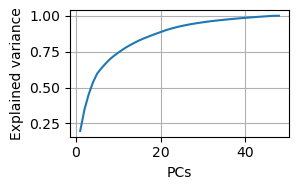

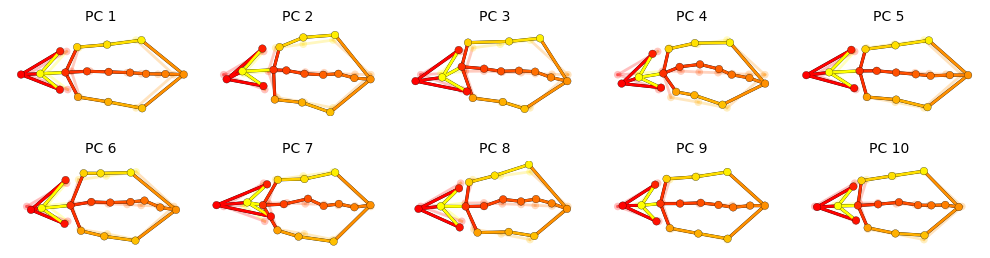

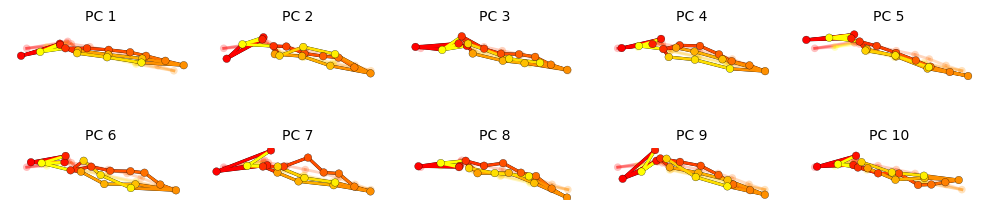

Saved interactive plot to jonathan_ifdn/pcs.html


In [22]:
pca = kpms.fit_pca(**data, **config())
kpms.save_pca(pca, project_dir)

kpms.print_dims_to_explain_variance(pca, 0.9)
kpms.plot_scree(pca, project_dir=project_dir)
kpms.plot_pcs(pca, project_dir=project_dir, **config())
kpms.update_config(project_dir, latent_dim=8)

In [17]:
import logging
from tqdm import tqdm  # Ensure tqdm is imported if not already
from jax_moseq.utils import get_durations
import jax

def run_opt_kappa(model_idx, data, pca, metadata, project_dir):
    # OPT_KAPPA = 4.207e+05
    OPT_KAPPA = 1.205e+06
    kappa = OPT_KAPPA
    logging.info(f"Model {model_idx}: Starting AR-only fitting with kappa={kappa}")

    # --- AR-only fitting ---
    model = kpms.init_model(data, pca=pca, **config(), seed=jax.random.PRNGKey(model_idx))
    num_ar_iters = 50
    model = kpms.update_hypparams(model, kappa=kappa)
    model, model_name = kpms.fit_model(
        model, data, metadata, project_dir,
        ar_only=True, num_iters=num_ar_iters)
    
    logging.info(f"Model {model_idx}: Completed AR-only fitting for model '{model_name}'. Loading checkpoint.")
    # Load the checkpoint after AR fitting.
    model, data, metadata, current_iter = kpms.load_checkpoint(
        project_dir, model_name, iteration=num_ar_iters)
    
    # --- Non-AR fitting ---
    fitting_iters = 300
    logging.info(f"Model {model_idx}: Starting non-AR fitting with adjusted kappa={kappa/10}.")
    model = kpms.update_hypparams(model, kappa=kappa/10)
    model_name = f'kappa_opt_2d_multiple{kappa:.3e}_{model_idx}'
    model = kpms.fit_model(
        model, data, metadata, project_dir, model_name,
        ar_only=False, start_iter=current_iter, num_iters=current_iter + fitting_iters)[0]
    logging.info(f"Model {model_idx}: Completed non-AR fitting. Final model name: '{model_name}'.")
    kpms.reindex_syllables_in_checkpoint(project_dir, model_name)

    
    return model, model_name

In [18]:
anlib_param_to_folder_prefix = {
    'conf_0.5_smooth_0.5': 'kappa_opt_adj_var2.915e+05',
    'conf_0.5_smooth_0.8': 'kappa_opt_0.5_smooth_0.8_1.278e+06',
    'conf_0.8_smooth_0.5': 'kappa_opt_0.8_smooth_0.5_4.207e+05',
    'conf_0.8_smooth_0.8': 'kappa_opt_conf_0.8_smooth_0.8_1.278e+06'
}

In [ ]:
# Main loop over models
for model_idx in range(10):
    logging.info(f"Starting run for model index: {model_idx}")
    model, model_name = run_opt_kappa(model_idx, data, pca, metadata, project_dir)
    
    # # Process batches and apply model
    # for i, (coords_batch, confs_batch) in enumerate(tqdm(zip(batches_coords, batches_confs), total=len(batches_coords))):
    #     logging.info(f"Model '{model_name}': Processing batch {i}")
    #     data_batch, metadata_batch = kpms.format_data(coords_batch, confs_batch, **config())
    #     results = kpms.apply_model(model, data_batch, metadata_batch, project_dir, model_name, **config())
        
    #     # Append the batch index to the save directory to make it unique.
    #     save_directory = f"{project_dir}/{model_name}/results_batch_{i}"
    #     kpms.save_results_as_csv(results, project_dir, model_name, save_dir=save_directory)
    #     logging.info(f"Model '{model_name}': Saved results for batch {i} to '{save_directory}'")
    
    # logging.info(f"Completed all batches for model '{model_name}'")


In [20]:
anlib_param_to_opt_model = {
'conf_0.5_smooth_0.5':'kappa_opt_adj_var2.915e+05_6',
'conf_0.5_smooth_0.8':'kappa_opt_0.5_smooth_0.8_1.278e+06_9',
'conf_0.8_smooth_0.5':'kappa_opt_0.8_smooth_0.5_4.207e+05_1',
'conf_0.8_smooth_0.8':'kappa_opt_conf_0.8_smooth_0.8_1.278e+06_3'
}

In [ ]:
import os
import logging
from tqdm import tqdm
import numpy as np

# Discover model directories: these are folders starting with "kappa_opt_",
# that do not have "_first" in their name, and that contain a checkpoint file.
model_names = [
    d for d in os.listdir(project_dir)
    if os.path.isdir(os.path.join(project_dir, d))
    and d.startswith('kappa_opt_2d_multiple1.205e+06' + '_')
    and os.path.exists(os.path.join(project_dir, d, "checkpoint.h5"))
]

print(len(model_names))
logging.info("Computing expected marginal likelihood (EML) scores for models...")

# Option A: Use the vectorized function, wrapping the call in tqdm for a progress update.
eml_scores, eml_std_errs = kpms.expected_marginal_likelihoods(project_dir, model_names, num_samples=5)

# Identify the best model (highest EML score)
best_model = model_names[np.argmax(eml_scores)]
logging.info(f"Best model: {best_model} (params)")

# Plot the EML scores for all models
kpms.plot_eml_scores(eml_scores, eml_std_errs, model_names)


In [22]:
# 12, 5, 2

In [23]:
model_prefix = 'kappa_opt_2d_multiple1.205e+06_'
curr_models = [model_prefix + n for n in ['12', '5', '2']]
curr_model = curr_models[-1]

Saved results to
jonathan_ifdn/kappa_opt_2d_multiple1.205e+06_2/results.h5


Reindexing: 100%|███████████| 13/13 [00:03<00:00,  3.48model snapshot/s]


Saving trajectory plots to jonathan_ifdn/kappa_opt_2d_multiple1.205e+06_2/trajectory_plots


Generating trajectory plots: 100%|██████| 96/96 [00:24<00:00,  3.94it/s]


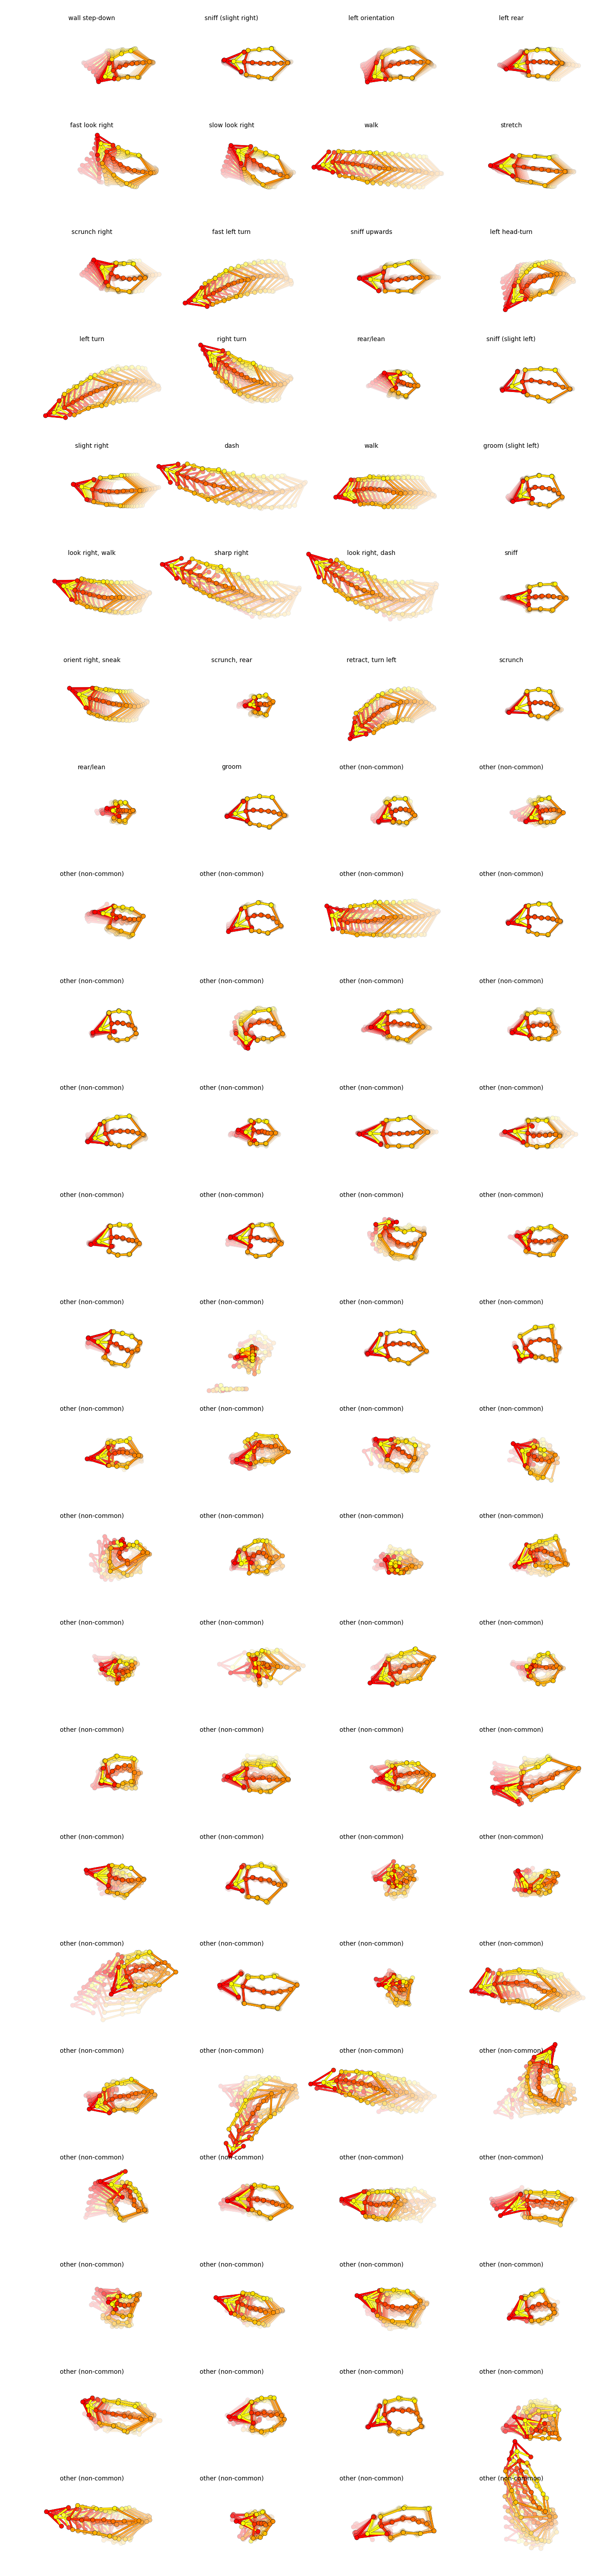

In [24]:
# for curr_model in curr_models:
model, data, metadata, current_iter = kpms.load_checkpoint(project_dir, curr_model)
results = kpms.extract_results(model, metadata, project_dir, curr_model)
# kpms.save_results_as_csv(results, project_dir, curr_model)
kpms.reindex_syllables_in_checkpoint(project_dir, curr_model)
kpms.generate_trajectory_plots(init_coords, results, project_dir, curr_model, density_sample=False, **config())
# kpms.plot_similarity_dendrogram(init_coords, results, project_dir, curr_model, **config())


In [25]:
video_dir = '/home/fsp585/Desktop/jonathan_ifdn_3d_poses/SplitWithGPU_link'
video_paths = kpms.find_matching_videos(results.keys(), video_dir, as_dict=True)

In [ ]:
# relative_video_indexes = video_frame_indexes[res_key] - video_frame_indexes[res_key][0]
# coordinates_2D[res_key] = coordinates_2D[res_key][relative_video_indexes]
# # coordinates_2D[res_key] = coordinates_2D[res_key][video_frame_indexes[res_key]]

centroids, headings = kpms.get_centroids_headings(init_coords, **config())

In [28]:
kpms.generate_grid_movies(
    results,
    project_dir,
    curr_model,
    video_paths=video_paths,
    coordinates=init_coords,
    centroids=centroids,
    headings=headings,
    fps=60,
    video_frame_indexes=video_frame_indexes,
    **config()
)

Writing grid movies to jonathan_ifdn/kappa_opt_2d_multiple1.205e+06_2/grid_movies
Using window size of 128 pixels


Generating grid movies: 100%|███████████| 48/48 [01:03<00:00,  1.32s/it]


{0: [('Arena1234_CenterTopCamVid_2024-12-16T14_05_53_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020',
   181472,
   181479),
  ('Arena1234_CenterTopCamVid_2024-12-13T14_50_39_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020',
   34956,
   34982),
  ('Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020',
   191614,
   191627),
  ('Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020',
   94692,
   94716),
  ('Arena1234_CenterTopCamVid_2024-12-16T14_05_53_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020',
   102578,
   102598),
  ('Arena1234_CenterTopCamVid_2024-12-16T11_27_19_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part2',
   197678,
   197708),
  ('Arena1234_CenterTopCamVid_2024-12-16T14_05_53_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10

In [33]:
kpms.interactive_group_setting(project_dir, curr_model)

Row
    [0] Tabulator(editors={'name': None, ...}, show_index=False, titles={'name': 'recording name',...}, value=              ..., widths={'name': 400})
    [1] Column
        [0] Button(button_type='primary', name='Save group info')

In [34]:
moseq_df = kpms.compute_moseq_df(project_dir, curr_model, smooth_heading=True)

In [36]:
kpms.label_syllables(project_dir, curr_model, moseq_df)

Row
    [0] Column
        [0] Select(options=[0, 1, 2, 3, 4, ...], value=0)
        [1] ParamFunction(function, _pane=Video)
    [1] Column
        [0] Tabulator(editors={'name': None, ...}, show_index=False, titles={'syllable': 'syllable', ...}, value=    syllable l..., widths={'syllable': 100})
        [1] Column
            [0] Button(button_type='primary', name='Save syllable info')

In [29]:
video_frame_indexes

{'Arena1234_CenterTopCamVid_2024-12-13T12_20_06_bottom_rightDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020': array([ 92167,  92168,  92169, ..., 310627, 310628, 310629]),
 'Arena1234_CenterTopCamVid_2024-12-13T13_37_45_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020': array([ 19499,  19500,  19501, ..., 242293, 242294, 242295]),
 'Arena1234_CenterTopCamVid_2024-12-13T14_50_39_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020': array([ 41519,  41520,  41521, ..., 263364, 263365, 263366]),
 'Arena1234_CenterTopCamVid_2024-12-16T11_27_19_bottom_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1': array([ 66190,  66191,  66192, ..., 272998, 272999, 273000]),
 'Arena1234_CenterTopCamVid_2024-12-16T11_27_19_top_leftDLC_HrnetW32_dataset_fixDec16shuffle10_detector_020_snapshot_020_part1': array([39295, 39296, 39297, ..., 73416, 73417, 73418]),
 'Arena1234_CenterTopCamVid_2024-12-16T11_27_19_top_leftDLC

In [30]:
import pickle

with open("video_frame_indexes.pkl", "wb") as f:
    pickle.dump(video_frame_indexes, f)